Easy for trees dataset subset and old SDD fitness function 

In [1]:
import multiprocessing
multiprocessing.set_start_method("spawn", force=True)

import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold

# Project root
PROJECT_ROOT = Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import sys
from pathlib import Path

# Find project root automatically
PROJECT_ROOT = Path.cwd().parents[1]

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees


In [3]:
from core.metrics import evaluate_tree_new
from evolution.encode_decode import decode
from evolution.genetic_DT_GA_Multi import evolve_trees, _load_dataset_csv

In [4]:
def eval_gene_on_dataset(gene, X, y, k=5, seed=123):

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)

    scores = []

    for tr, te in skf.split(X, y):

        algo = decode(gene)
        algo.fit(X[tr], y[tr])

        m = evaluate_tree_new(algo, X[te], y[te])
        scores.append(m["f1"])

    return np.array(scores)

In [5]:
random.seed(42)

data_path = PROJECT_ROOT / "data"

# (15)
datasets = {
    "anneal": data_path / "anneal.csv",
    "car": data_path / "car.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "iris": data_path / "iris.csv",
    "banknote": data_path / "banknote_authentication.csv",
}

# (5)
unseen_datasets = {
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "credit_approval": data_path / "credit_approval.csv",
    "ionosphere": data_path / "ionosphere.csv",
}


target_cols = {name: None for name in list(datasets.keys()) + list(unseen_datasets.keys())}

In [6]:
mu = 25
lambd = 25
generations = 30

print("Starting Evolutionary Process...")
print(f"Experiment with mu={mu}, lambda={lambd} for {generations} generations.")
print("Training datasets:", list(datasets.keys()))

Starting Evolutionary Process...
Experiment with mu=25, lambda=25 for 30 generations.
Training datasets: ['anneal', 'car', 'tic_tac_toe', 'iris', 'banknote']


In [7]:
timestamp = time.strftime("%Y%m%d_%H%M")

results_dir = Path(
    r"C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs"
)

results_dir.mkdir(parents=True, exist_ok=True)

print("Figures will be saved in:", results_dir)

Figures will be saved in: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs


In [8]:
evo_t0 = time.time()

best_gene, best_fit, history, fitness_rank_history, generalization_history, generalization_sdd_history = evolve_trees(
    datasets,
    unseen_datasets,
    target_cols=target_cols,
    mu=mu,
    lambd=lambd,
    generations=generations)

evo_tf = time.time()


# Tiempo total
total_time = evo_tf - evo_t0
total_minutes = total_time / 60
total_hours = total_time / 3600

# Tiempo promedio por generación
time_per_gen = total_time / generations

print("\n ===== Evolution Summary =====")
print(f"Total time: {total_time:.2f} seconds")
print(f"Total time: {total_minutes:.2f} minutes")
print(f"Total time: {total_hours:.2f} hours")
print(f"Avg time per generation: {time_per_gen:.2f} seconds")

print("\n ===== Results =====")
print("Best gene:", best_gene)
print("Fitness (mean - SDD):", best_fit)


[Evaluation] 25 genes | 5 datasets | 5 folds | workers=18 | timeout=900s

[Progress] 1/25 [OK] gene=[4, 3, 20, 2, 1, 1, 2, 10] fitness=-8.5344 SDD=8.5344 total=66.81s pid=27972
  dataset mean F1 | best=0.9577 worst=0.7747 avg=0.8856
  xi values=[16.0656, 10.0351, 25.3887, 6.2118, 4.3181]
  - anneal               F1 mean=0.8513 best=0.9935 worst=0.7797 folds=[0.8121, 0.8238, 0.7797, 0.9935, 0.8474]
    time total=8.62s decode=0.00s fit=8.51s metrics=0.09s | depth=8.40 nodes=33.00
  - car                  F1 mean=0.9044 best=0.9506 worst=0.8808 folds=[0.8808, 0.9506, 0.9092, 0.8944, 0.8872]
    time total=26.39s decode=0.00s fit=26.27s metrics=0.11s | depth=25.00 nodes=331.40
  - tic_tac_toe          F1 mean=0.7747 best=0.8484 worst=0.6943 folds=[0.8282, 0.7285, 0.774, 0.8484, 0.6943]
    time total=20.87s decode=0.00s fit=20.77s metrics=0.09s | depth=22.20 nodes=215.00
  - iris                 F1 mean=0.9398 best=1.0000 worst=0.8995 folds=[1.0, 0.8995, 0.9332, 0.9327, 0.9333]
    time 

In [9]:
# Report generalization across datasets
for name, dataset_path in datasets.items():
    target_col = None if target_cols is None else target_cols.get(name, None)

    X, y = _load_dataset_csv(dataset_path, target_col=target_col)
    scores = eval_gene_on_dataset(best_gene, X, y, k=5)

    print(f"{name}: mean F1={scores.mean():.4f}, std F1={scores.std():.4f}, folds={scores}")

anneal: mean F1=0.9329, std F1=0.0780, folds=[0.78298937 0.97161993 0.93251701 1.         0.97724821]
car: mean F1=0.9390, std F1=0.0346, folds=[0.93621795 0.87730396 0.97236342 0.93725624 0.97165694]
tic_tac_toe: mean F1=0.8751, std F1=0.0329, folds=[0.85408117 0.91662531 0.83320852 0.86089738 0.91081712]
iris: mean F1=0.9400, std F1=0.0446, folds=[0.96658312 0.93460925 0.93333333 1.         0.86531987]
banknote: mean F1=0.9742, std F1=0.0104, folds=[0.96676469 0.96328242 0.97023033 0.9778711  0.99261217]


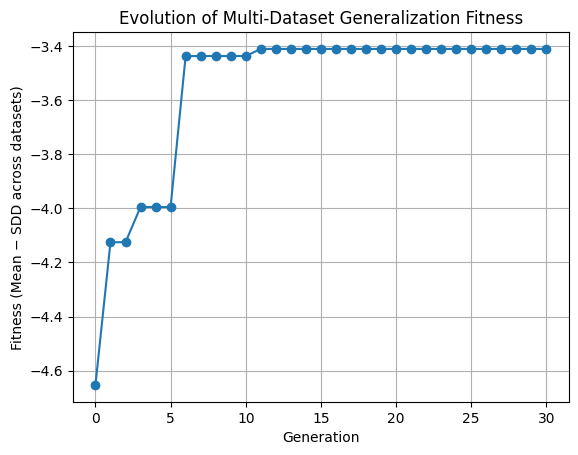

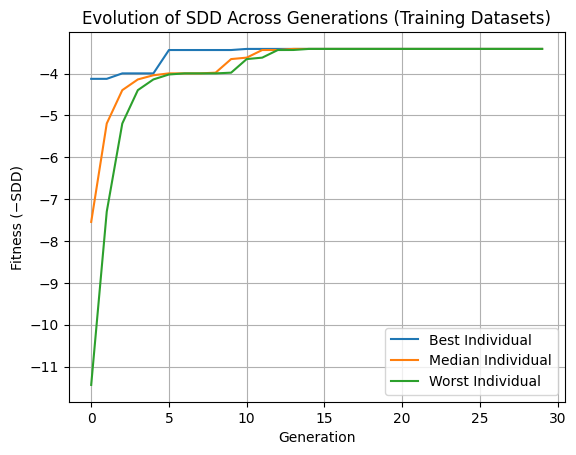

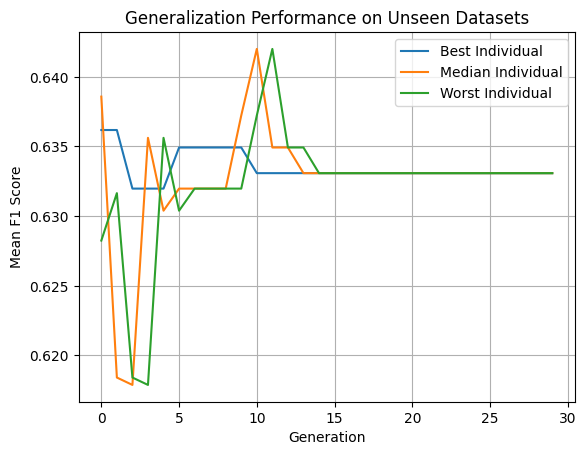

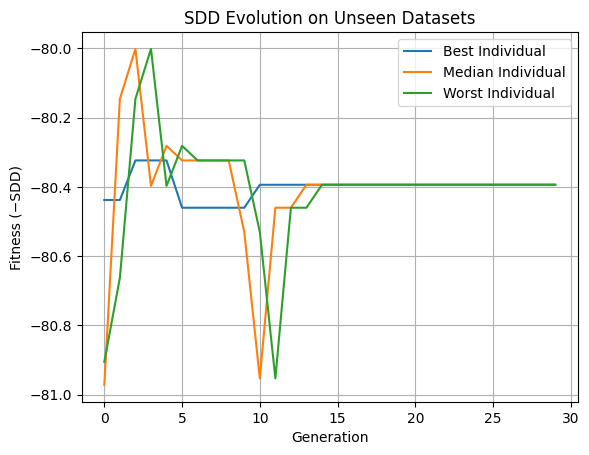

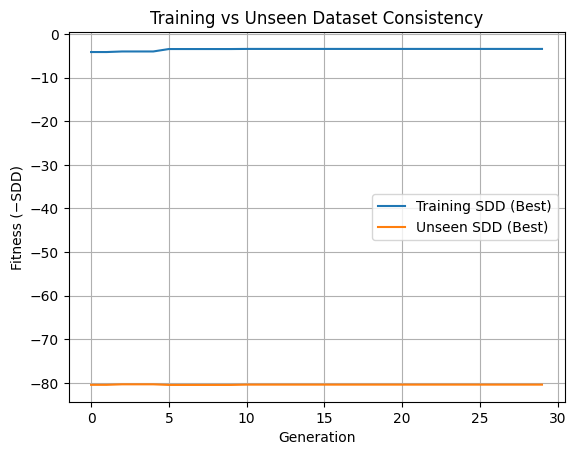

In [10]:
# Graph 1 — Best Fitness Evolution
fig = plt.figure()

plt.plot(history, marker="o")

plt.title("Evolution of Multi-Dataset Generalization Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Mean − SDD across datasets)")
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "fitness_evolution.png", dpi=300)



# Graph 2 — Training SDD Evolution
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Best Individual")
plt.plot(fitness_rank_history["median"], label="Median Individual")
plt.plot(fitness_rank_history["worst"], label="Worst Individual")

plt.title("Evolution of SDD Across Generations (Training Datasets)")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_sdd.png", dpi=300)



# Graph 3 — Generalization F1
fig = plt.figure()

plt.plot(generalization_history["best"], label="Best Individual")
plt.plot(generalization_history["median"], label="Median Individual")
plt.plot(generalization_history["worst"], label="Worst Individual")

plt.title("Generalization Performance on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Mean F1 Score")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "generalization_f1.png", dpi=300)



# Graph 4 — Unseen Dataset SDD
fig = plt.figure()

plt.plot(generalization_sdd_history["best"], label="Best Individual")
plt.plot(generalization_sdd_history["median"], label="Median Individual")
plt.plot(generalization_sdd_history["worst"], label="Worst Individual")

plt.title("SDD Evolution on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)

#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "unseen_sdd.png", dpi=300)



# Graph 5 — Training vs Unseen SDD
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Training SDD (Best)")
plt.plot(generalization_sdd_history["best"], label="Unseen SDD (Best)")

plt.title("Training vs Unseen Dataset Consistency")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_vs_unseen_sdd.png", dpi=300)

plt.show()